In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__notebook__.ipynb
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__output__.json
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results__.html
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/custom.css
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/submission.csv
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results___files/__results___105_0.png
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results___files/__results___20_1.png
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results___files/__results___23_0.png
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results___files/__results___24_0.png
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/__results___files/__results___6_1.png
/kaggle/input/notebooks/biploveee/23f1001103-notebook-2026t3/catboost_info/catboost_training.json
/kaggle/input/noteb

In [2]:
df_original = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv')
df = df_original.copy()
test_df = pd.read_csv('/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv')
test_clean = test_df.copy()

In [3]:
df.dtypes

space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
facilities                       object
snapshot_start_date              object
snapshot_end_date                object
min_term_days                   float64


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279746 entries, 0 to 279745
Data columns (total 60 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   space_id                      279746 non-null  int64  
 1   operator_ref                  279142 non-null  object 
 2   operator_platform_age_years   279142 non-null  float64
 3   operator_platform_age_months  279142 non-null  float64
 4   operator_active_years         279140 non-null  float64
 5   operator_active_months        279140 non-null  float64
 6   operator_class                279746 non-null  object 
 7   operator_certified            279142 non-null  object 
 8   operator_portfolio_size       279142 non-null  float64
 9   operator_has_avatar           279142 non-null  object 
 10  operator_id_verified          279142 non-null  object 
 11  zone                          279746 non-null  object 
 12  borough                       65295 non-null

In [5]:
df.dtypes

space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
facilities                       object
snapshot_start_date              object
snapshot_end_date                object
min_term_days                   float64


In [6]:
print(test_df)

        space_id operator_ref  operator_platform_age_years  \
0              0      Praklar                          2.0   
1              1       Draren                          2.0   
2              2    Sinnovara                          3.0   
3              3       Fehinn                          5.0   
4              4      Rothass                         11.0   
...          ...          ...                          ...   
114533    114533      Spogral                          6.0   
114534    114534        Kofle                          2.0   
114535    114535  Chesssnarta                          9.0   
114536    114536     Krukrota                          0.0   
114537    114537     Drelenss                          8.0   

        operator_platform_age_months  operator_active_years  \
0                               11.0                    2.0   
1                                6.0                    2.0   
2                                4.0                    3.0   
3  

price_tier
2    81530
4    70488
1    66889
3    60839
Name: count, dtype: int64


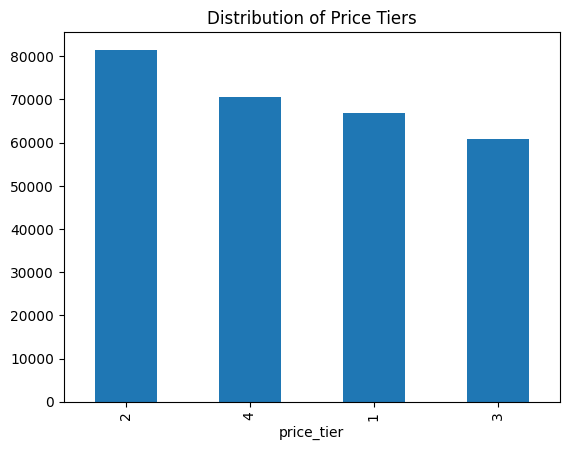

In [7]:
import matplotlib.pyplot as plt

target_counts = df_original['price_tier'].value_counts()
print(target_counts)

target_counts.plot(kind='bar', title='Distribution of Price Tiers')
plt.show()

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

In [9]:
x_raw = df.drop(columns="price_tier")
y_raw = df["price_tier"]

1)Dummy Model

In [10]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(x_raw, y_raw)

DummyClassifier(strategy='most_frequent')

In [11]:
dummy_pred = dummy_model.predict(test_df)

In [12]:
submission_dummy = pd.DataFrame({
    "ID" : test_df["space_id"],
    "price_tier": dummy_pred
})

In [13]:
# submission_dummy.to_csv('submission.csv', index=False)

2)Basic Analysis

In [14]:
df.dtypes.value_counts()

float64    26
int64      17
object     17
Name: count, dtype: int64

In [15]:
# df.info()
df.describe()

,space_id,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_portfolio_size,geo_lat,geo_lon,max_seats,utility_rooms,...,score_onboarding,score_support,score_access,score_value,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,price_tier
count,279746.00000,279142.000000,279142.000000,279140.000000,279140.000000,279142.000000,279746.000000,279746.000000,279746.000000,249847.000000,...,225503.000000,225505.000000,225501.000000,225500.000000,279746.000000,279746.000000,279746.000000,279746.000000,225506.000000,279746.000000
mean,139872.50000,6.794735,5.453275,5.083295,5.298635,49.472043,77.766908,-35.144810,3.627312,1.358645,...,9.633323,9.651561,9.559088,9.302167,22.630883,18.468203,3.905736,0.098940,1.528739,2.482316
std,80755.85854,4.187652,3.489590,4.040029,3.480848,332.752235,37.513760,57.170057,2.277564,0.806307,...,0.750909,0.772645,0.718961,0.915583,58.731714,54.515981,19.515136,1.370754,1.808781,1.109886
min,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,-4.818000,-123.749800,1.000000,0.500000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000,1.000000
25%,69936.25000,3.000000,2.000000,2.000000,2.000000,1.000000,68.041500,-76.559800,2.000000,1.000000,...,9.600000,9.620000,9.420000,9.120000,1.000000,1.000000,0.000000,0.000000,0.340000,2.000000
50%,139872.50000,7.000000,5.000000,4.000000,5.000000,4.000000,94.623000,-31.132600,3.000000,1.000000,...,9.840000,9.880000,9.760000,9.520000,3.000000,2.000000,0.000000,0.000000,1.000000,2.000000
75%,209808.75000,10.000000,9.000000,8.000000,8.000000,19.000000,100.941000,-21.265600,4.000000,1.500000,...,10.000000,10.000000,10.000000,9.800000,15.000000,10.000000,1.000000,0.000000,2.190000,4.000000
max,279745.00000,17.000000,11.000000,15.000000,11.000000,5978.000000,111.768000,87.045200,16.000000,50.000000,...,10.000000,10.000000,10.000000,10.000000,754.000000,754.000000,233.000000,62.000000,150.180000,4.000000


In [16]:
df.isna().sum().sort_values(ascending=False).head(10)

borough              214451
score_value           54246
score_access          54245
score_onboarding      54243
score_accuracy        54242
score_support         54241
first_review_date     54240
last_review_date      54240
score_condition       54240
reviews_per_month     54240
dtype: int64

In [17]:
# df.info()

print(df.isna().mean().sort_values(ascending=False).head(15))
# print(df['price_tier'].value_counts(normalize=True))


borough                   0.766592
score_value               0.193912
score_access              0.193908
score_onboarding          0.193901
score_accuracy            0.193897
score_support             0.193894
first_review_date         0.193890
last_review_date          0.193890
score_condition           0.193890
reviews_per_month         0.193890
score_overall             0.193876
zones                     0.173064
utility_rooms             0.106879
workstations              0.067143
operator_active_months    0.002166
dtype: float64


In [18]:
df['operator_ref'].value_counts(normalize=True)
df['operator_ref'].nunique()

41903

Highly correlated/redundant features to monitor: ['min_term_floor', 'max_term_ceiling', 'min_term_avg', 'open_slots_b', 'open_slots_c', 'open_slots_e', 'review_count_prev_yr', 'score_accuracy', 'score_condition', 'score_value', 'operator_metro_whole', 'reviews_per_month']


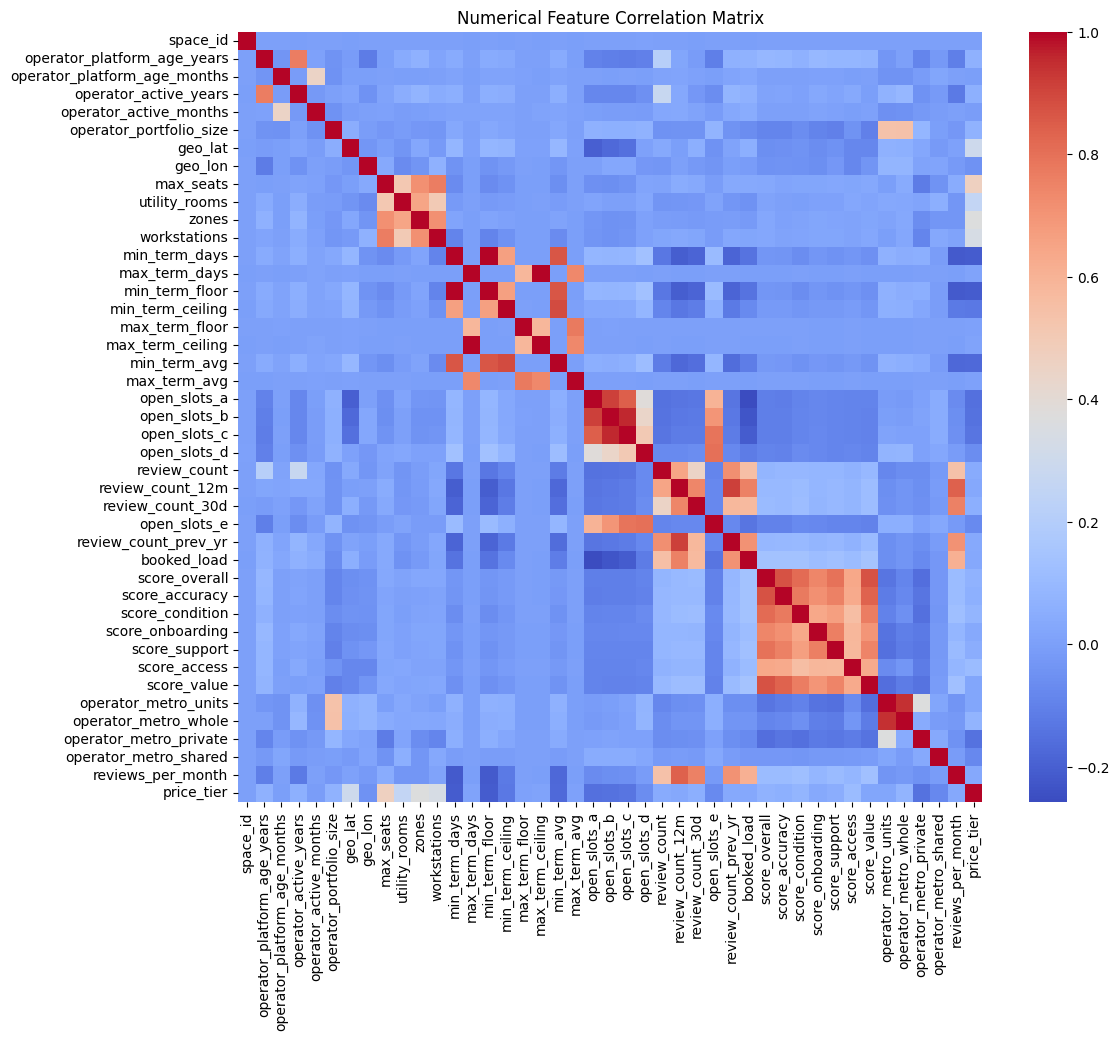

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

num_df = df.select_dtypes(include=[np.number])

corr_matrix = num_df.corr()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
highly_correlated = [column for column in upper_tri.columns if any(upper_tri[column] > 0.8)]
print(f"Highly correlated/redundant features to monitor: {highly_correlated}")

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Numerical Feature Correlation Matrix")
plt.show()

In [20]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
print(df.select_dtypes(include='object').nunique().sort_values(ascending=False))

facilities              251649
operator_ref             41903
first_review_date         5342
last_review_date          3287
zone                      1380
snapshot_end_date          384
snapshot_start_date        383
space_class                131
borough                     55
metro                       16
access_type                  4
compliance_status            4
operator_class               3
operator_has_avatar          2
operator_certified           2
operator_id_verified         2
bookable                     2
dtype: int64


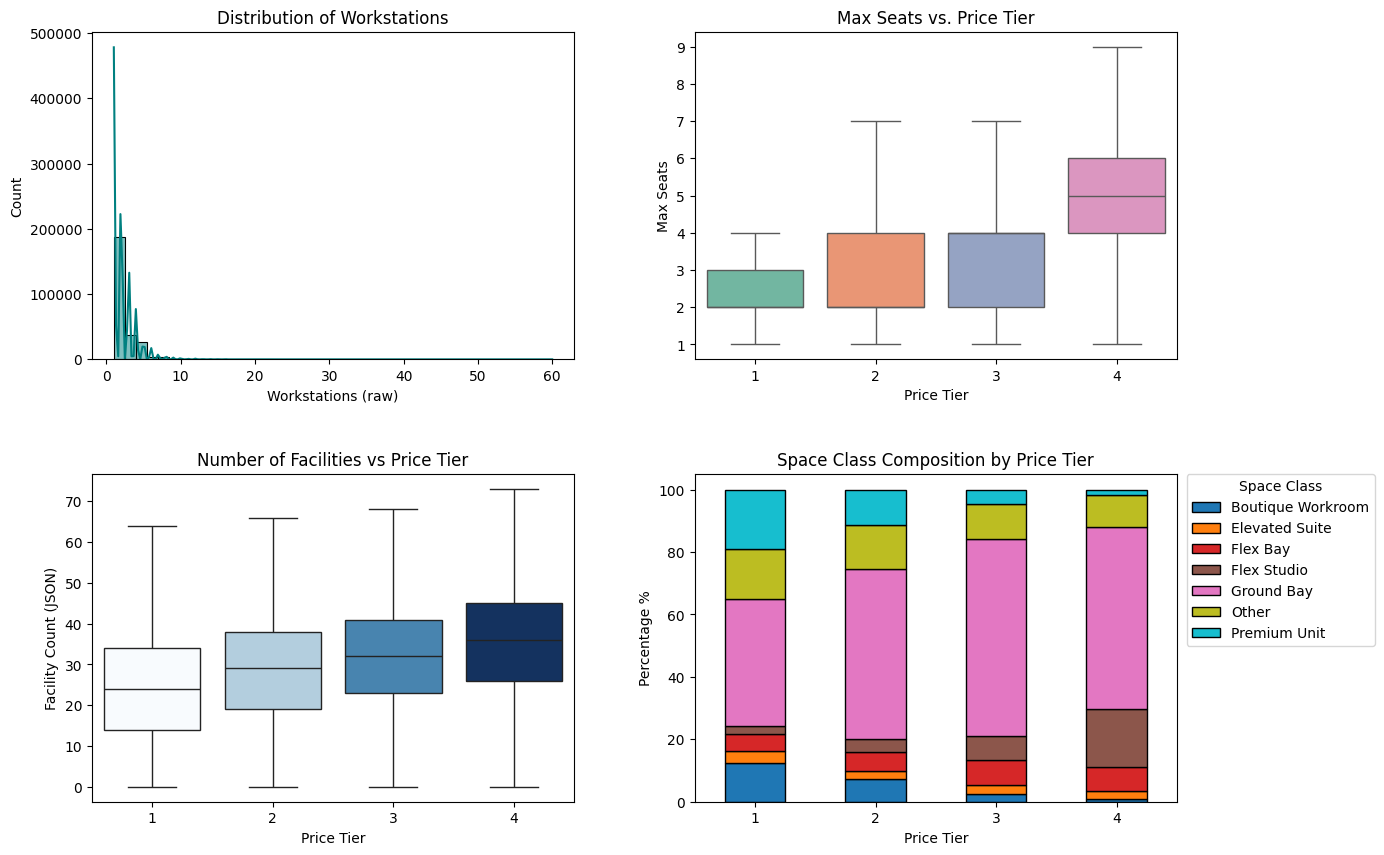

In [22]:
df['temp_facility_count'] = df['facilities'].apply(lambda x: len(json.loads(x)) if isinstance(x, str) else 0)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

sns.histplot(df['workstations'].dropna(), bins=40, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Workstations')
axes[0, 0].set_xlabel('Workstations (raw)')

sns.boxplot(data=df, x='price_tier', y='max_seats', showfliers=False, ax=axes[0, 1], palette='Set2', hue='price_tier', legend=False)
axes[0, 1].set_title('Max Seats vs. Price Tier')
axes[0, 1].set_xlabel('Price Tier')
axes[0, 1].set_ylabel('Max Seats')

sns.boxplot(data=df, x='price_tier', y='temp_facility_count', hue='price_tier', legend=False, showfliers=False, ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('Number of Facilities vs Price Tier')
axes[1, 0].set_xlabel('Price Tier')
axes[1, 0].set_ylabel('Facility Count (JSON)')

top_classes = df['space_class'].value_counts().nlargest(6).index
filtered_classes = df['space_class'].apply(
    lambda x: x if x in top_classes else 'Other'
)

ct = pd.crosstab(df['price_tier'], filtered_classes, normalize='index') * 100

ct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1, 1],
    colormap='tab10',
    edgecolor='black',
)

axes[1, 1].set_title('Space Class Composition by Price Tier')
axes[1, 1].set_xlabel('Price Tier')
axes[1, 1].set_ylabel('Percentage %')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].legend(
    title='Space Class',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0,
)

plt.show()

df.drop(columns=['temp_facility_count'], errors='ignore', inplace=True)

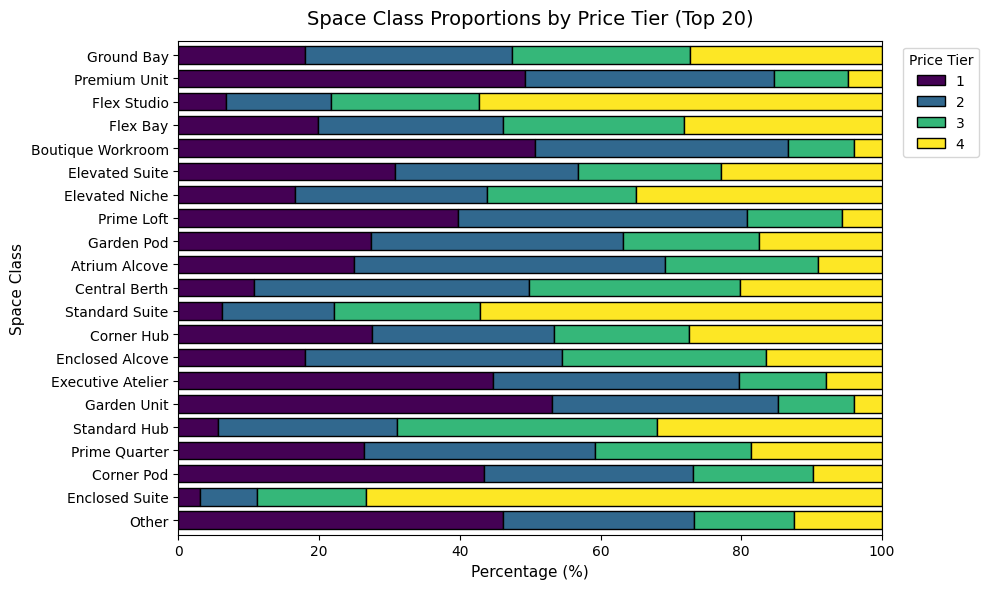

In [23]:
n = 20
top_classes = df['space_class'].value_counts().nlargest(n).index
filtered_classes = df['space_class'].apply(
    lambda x: x if x in top_classes else 'Other'
)

order = list(top_classes) + ['Other']
ct = (
    pd.crosstab(filtered_classes, df['price_tier'], normalize='index') * 100
).loc[order]

fig, ax = plt.subplots(figsize=(10, 6))

ct.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    colormap='viridis',
    edgecolor='black',
    width=0.75,
)

ax.invert_yaxis()
ax.set_title(f'Space Class Proportions by Price Tier (Top {n})', fontsize=14, pad=12,)
ax.set_xlabel('Percentage (%)', fontsize=11)
ax.set_ylabel('Space Class', fontsize=11)
ax.set_xlim(0, 100)
ax.legend(
    title='Price Tier',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)

plt.tight_layout()
plt.show()

In [24]:
drop_cols = ['operator_ref', 'borough', 'space_id', 'snapshot_start_date', 'last_review_date', 'first_review_date', 'snapshot_end_date']
df_clean = df.drop(columns=drop_cols).copy()
x_full = x_raw.drop(columns=drop_cols).copy()
test_clean = test_df.drop(columns=drop_cols).copy()

x_clean = df_clean.drop(columns='price_tier')
y_clean = df_clean['price_tier']

x_train, x_test, y_train, y_test = train_test_split(x_clean, y_clean, test_size = 0.2, stratify = y_clean, random_state = 42)

In [25]:
skewed = df_clean.skew(numeric_only=True)
skewed.sort_values(ascending=False).head(15)

max_term_floor             200.185455
max_term_avg               166.050416
max_term_days              118.313582
max_term_ceiling           118.313582
operator_metro_shared       23.248705
operator_portfolio_size     16.078370
min_term_ceiling            12.883943
review_count_12m            10.380401
reviews_per_month            9.882703
operator_metro_private       8.797785
review_count_30d             8.600692
min_term_avg                 8.314109
review_count_prev_yr         8.220725
utility_rooms                7.384439
zones                        6.682692
dtype: float64

In [26]:
right_skewed_cols = skewed[skewed > 1].index.tolist()
x_train[right_skewed_cols] = np.log1p(x_train[right_skewed_cols])
x_test[right_skewed_cols] = np.log1p(x_test[right_skewed_cols])
x_full[right_skewed_cols] = np.log1p(x_full[right_skewed_cols])
test_clean[right_skewed_cols] = np.log1p(test_clean[right_skewed_cols])

**EDA (Exploratory data analysis) insights**
1. Target distribution : *price_tier* consists of 4 classes and is almost equally distrbuted slightly favouring tier 2.
2. Missing Values : *borough* is missing in 76%+ rows and 7 review columns (*score_overall, score_value *etc) are missing in approximately 20% of the rows, which may be of new workspaces
3. High cardinality + json : *operator_ref* has 41000+ unique id and facilities has 251000+ unique json strings, but parsing the json list in facilities shows strong positive correlation between number of facilities and *price_tier*
4. Feature skewness : features like *max_term_floor, operator_portfolio_size, workstations* are heavily skewed (right skew (>1)) and 12 numerical features have correlation >.80 . For distance/gradient-based models, we must apply log transformation, median imputation, and StandardScaler.

# 3) # preprocessing and baseline models

In [27]:
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = x_train.select_dtypes(include=['object']).columns

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', max_categories=20))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# **LogisticRegression Model**

In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [29]:
from sklearn.linear_model import LogisticRegression

log_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(solver='saga', max_iter=200, n_jobs=-1))
])

param_grid = {
    "preprocessor__num__imputer__strategy" : ["mean", "median"],
    "preprocessor__num__scaler" : [StandardScaler(), MinMaxScaler(), RobustScaler()],
    "preprocessor__cat__imputer__strategy" : ["most_frequent", "constant"],
    "classifier__C" : [0.01, 0.1, 1.0, 10.0]
}

random_search = RandomizedSearchCV(
    log_pipe,
    param_grid,
    n_iter=3,
    cv=2,
    scoring='accuracy',
    verbose=2,
    n_jobs=1
)


In [30]:
random_search.fit(x_train, y_train)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END classifier__C=0.1, preprocessor__cat__imputer__strategy=constant, preprocessor__num__imputer__strategy=median, preprocessor__num__scaler=StandardScaler(); total time= 1.3min
[CV] END classifier__C=0.1, preprocessor__cat__imputer__strategy=constant, preprocessor__num__imputer__strategy=median, preprocessor__num__scaler=StandardScaler(); total time= 1.2min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END classifier__C=1.0, preprocessor__cat__imputer__strategy=constant, preprocessor__num__imputer__strategy=mean, preprocessor__num__scaler=RobustScaler(); total time= 1.6min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END classifier__C=1.0, preprocessor__cat__imputer__strategy=constant, preprocessor__num__imputer__strategy=mean, preprocessor__num__scaler=RobustScaler(); total time= 1.6min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END classifier__C=1.0, preprocessor__cat__imputer__strategy=most_frequent, preprocessor__num__imputer__strategy=median, preprocessor__num__scaler=MinMaxScaler(); total time= 1.6min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END classifier__C=1.0, preprocessor__cat__imputer__strategy=most_frequent, preprocessor__num__imputer__strategy=median, preprocessor__num__scaler=MinMaxScaler(); total time= 1.6min


RandomizedSearchCV(cv=2,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', '...
                                              LogisticRegression(max_iter=200,
                                                                 n_jobs=-1,
                                                                 solver='saga'))]),
                   n_iter=3, n_jobs=1,
                   param_distributions={'classifier__C': [0.01, 0.1, 1.0, 10.0],
                                        'preprocessor__cat__imputer__strategy': ['most_frequent',
                                                                                 'constant'],
                                        'preprocessor__num__imputer__strategy': ['mean',
                                                                                 'median'],
                                        'preprocessor__num__scaler': [StandardScaler(),
                                                                      MinMaxScaler(),
                                                                      RobustScaler()]},
                   scoring='accuracy', verbose=2)

In [31]:
log_pred = random_search.predict(x_test)
log_accuracy = accuracy_score(y_test, log_pred)
log_class_rep = classification_report(y_test, log_pred)

print(log_accuracy)
print(log_class_rep)

0.6229848078641644
              precision    recall  f1-score   support

           1       0.66      0.84      0.74     13378
           2       0.57      0.54      0.55     16306
           3       0.53      0.28      0.37     12168
           4       0.67      0.80      0.73     14098

    accuracy                           0.62     55950
   macro avg       0.61      0.62      0.60     55950
weighted avg       0.61      0.62      0.60     55950



In [32]:
print(log_accuracy)
print(log_class_rep)

0.6229848078641644
              precision    recall  f1-score   support

           1       0.66      0.84      0.74     13378
           2       0.57      0.54      0.55     16306
           3       0.53      0.28      0.37     12168
           4       0.67      0.80      0.73     14098

    accuracy                           0.62     55950
   macro avg       0.61      0.62      0.60     55950
weighted avg       0.61      0.62      0.60     55950



In [33]:
sub_id = test_df['space_id']

In [34]:
final_log_pred = random_search.predict(test_clean)

submission_df = pd.DataFrame({
    'ID' : sub_id,
    'price_tier' : final_log_pred
})

# submission_df.to_csv('submission.csv', index=False)

# **Multi Layer Perceptron**

In [35]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OrdinalEncoder

In [36]:
mlp_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        early_stopping=True, random_state=42
    ))
])

mlp_param_grid = {
    "classifier__hidden_layer_sizes" : [(32,), (50,)],
    "classifier__alpha" : [0.001, 0.01],
    "classifier__learning_rate_init" : [0.001, 0.01]
}

mlp_search = RandomizedSearchCV(
    mlp_pipe,
    mlp_param_grid,
    n_iter=2,
    cv=2,
    scoring='accuracy',
    verbose=2,
    n_jobs=1,
    random_state=42
)

In [37]:
mlp_search.fit(x_train, y_train)

Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END classifier__alpha=0.001, classifier__hidden_layer_sizes=(32,), classifier__learning_rate_init=0.01; total time=  25.2s
[CV] END classifier__alpha=0.001, classifier__hidden_layer_sizes=(32,), classifier__learning_rate_init=0.01; total time=  25.3s
[CV] END classifier__alpha=0.01, classifier__hidden_layer_sizes=(32,), classifier__learning_rate_init=0.01; total time=  21.9s
[CV] END classifier__alpha=0.01, classifier__hidden_layer_sizes=(32,), classifier__learning_rate_init=0.01; total time=  14.0s


RandomizedSearchCV(cv=2,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', '...
       'facilities', 'bookable', 'compliance_status', 'metro'],
      dtype='object'))])),
                                             ('classifier',
                                              MLPClassifier(early_stopping=True,
                                                            random_state=42))]),
                   n_iter=2, n_jobs=1,
                   param_distributions={'classifier__alpha': [0.001, 0.01],
                                        'classifier__hidden_layer_sizes': [(32,),
                                                                           (50,)],
                                        'classifier__learning_rate_init': [0.001,
                                                                           0.01]},
                   random_state=42, scoring='accuracy', verbose=2)

In [38]:
mlp_pred = mlp_search.predict(x_test)
print(accuracy_score(y_test, mlp_pred))
print(mlp_search.best_params_)

0.6676675603217158
{'classifier__learning_rate_init': 0.01, 'classifier__hidden_layer_sizes': (32,), 'classifier__alpha': 0.001}


In [39]:
mlp_final_pred = mlp_search.predict(test_clean)

mlp_sub_df = pd.DataFrame({
    'ID' : sub_id,
    "price_tier" : mlp_final_pred
})

# mlp_sub_df.to_csv("mlp_submission.csv", index=False)

1. LogisticRegression and MLPClassifier achieved around 0.62 - 0.65 accuracy score.
2. This was mainly because the price_tier depends upon non linear things
3. Switching to tree-based models to capture non linear relationships using OrdinalEncoder and TargetEncoder instead of OneHotEncoder

# **HistGradientBoost**

In [40]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

In [41]:
hist_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

hist_num_pipe = SimpleImputer(strategy='median')

preprocessor_tree = ColumnTransformer([
    ("num", hist_num_pipe, num_cols),
    ("cat", hist_cat_pipe, cat_cols)
])


histGB_pipe = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", HistGradientBoostingClassifier(max_iter = 700, learning_rate = 0.05, random_state=42, min_samples_leaf=50, max_leaf_nodes = 50, l2_regularization = 5.0))
])

In [42]:
histGB_pipe.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', 'geo_lon', 'max_seats',
       'utility_rooms', 'zones', 'workstations', 'min_term_days',
       'max_term_days',...
                                                  Index(['operator_class', 'operator_certified', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'space_class', 'access_type',
       'facilities', 'bookable', 'compliance_status', 'metro'],
      dtype='object'))])),
                ('classifier',
                 HistGradientBoostingClassifier(l2_regularization=5.0,
                                                learning_rate=0.05,
                                                max_iter=700, max_leaf_nodes=50,
                                                min_samples_leaf=50,
                                                random_state=42))])

In [43]:
histGB_pred = histGB_pipe.predict(x_test)
histGB_accuracy = accuracy_score(y_test, histGB_pred)
histGB_class_rep = classification_report(y_test, histGB_pred)

print(histGB_accuracy)
print(histGB_class_rep)

0.7138337801608579
              precision    recall  f1-score   support

           1       0.80      0.83      0.82     13378
           2       0.64      0.72      0.68     16306
           3       0.59      0.50      0.54     12168
           4       0.81      0.78      0.79     14098

    accuracy                           0.71     55950
   macro avg       0.71      0.71      0.71     55950
weighted avg       0.71      0.71      0.71     55950



In [44]:
# histGB_pipe.fit(x_full, y_raw)

In [45]:
# histGB_sub_df = pd.DataFrame({
#     "ID" : sub_id,
#     "price_tier" : histGB_pipe.predict(test_clean)
# })

# histGB_sub_df.to_csv("histGB_submission.csv", index=False)

# **HistGradientBoosting para TUNING**

In [46]:
histGB_param_grid = {
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_iter': [100, 200, 300, 500],
    'classifier__max_leaf_nodes': [31, 50, 75, 100],
    'classifier__l2_regularization': [0.0, 0.1, 1.0]
}

histGB_search = RandomizedSearchCV(
    histGB_pipe, 
    histGB_param_grid,
    n_iter=3, 
    cv=2, 
    scoring='accuracy',
    verbose=2,
    n_jobs=1,
    random_state=42
)

histGB_search.fit(x_train, y_train)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END classifier__l2_regularization=0.0, classifier__learning_rate=0.1, classifier__max_iter=500, classifier__max_leaf_nodes=50; total time=  52.8s
[CV] END classifier__l2_regularization=0.0, classifier__learning_rate=0.1, classifier__max_iter=500, classifier__max_leaf_nodes=50; total time=  43.5s
[CV] END classifier__l2_regularization=1.0, classifier__learning_rate=0.01, classifier__max_iter=300, classifier__max_leaf_nodes=31; total time=  52.2s
[CV] END classifier__l2_regularization=1.0, classifier__learning_rate=0.01, classifier__max_iter=300, classifier__max_leaf_nodes=31; total time=  53.6s
[CV] END classifier__l2_regularization=0.1, classifier__learning_rate=0.01, classifier__max_iter=500, classifier__max_leaf_nodes=31; total time= 1.4min
[CV] END classifier__l2_regularization=0.1, classifier__learning_rate=0.01, classifier__max_iter=500, classifier__max_leaf_nodes=31; total time= 1.4min


RandomizedSearchCV(cv=2,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               SimpleImputer(strategy='median'),
                                                                               Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', 'geo_lon', 'max_seats',
       'utility_rooms', 'zones', 'workstations...
                                                                             learning_rate=0.05,
                                                                             max_iter=700,
                                                                             max_leaf_nodes=50,
                                                                             min_samples_leaf=50,
                                                                             random_state=42))]),
                   n_iter=3, n_jobs=1,
                   param_distributions={'classifier__l2_regularization': [0.0,
                                                                          0.1,
                                                                          1.0],
                                        'classifier__learning_rate': [0.01,
                                                                      0.05, 0.1,
                                                                      0.2],
                                        'classifier__max_iter': [100, 200, 300,
                                                                 500],
                                        'classifier__max_leaf_nodes': [31, 50,
                                                                       75,
                                                                       100]},
                   random_state=42, scoring='accuracy', verbose=2)

In [47]:
histGB_best_params = histGB_search.best_params_
tuned_histGB_pred = histGB_search.predict(x_test)
tuned_histGB_accuracy = accuracy_score(y_test, tuned_histGB_pred)
tuned_histGB_class_rep = classification_report(y_test, tuned_histGB_pred)

print(f"tuned histGB best parameters {histGB_best_params}")
print(f"tuned histGB accuracy score {tuned_histGB_accuracy}")
print(f"tuned histGB classification report {tuned_histGB_class_rep}")

tuned histGB best parameters {'classifier__max_leaf_nodes': 50, 'classifier__max_iter': 500, 'classifier__learning_rate': 0.1, 'classifier__l2_regularization': 0.0}
tuned histGB accuracy score 0.7129579982126899
tuned histGB classification report               precision    recall  f1-score   support

           1       0.80      0.84      0.82     13378
           2       0.65      0.71      0.68     16306
           3       0.59      0.51      0.55     12168
           4       0.81      0.78      0.79     14098

    accuracy                           0.71     55950
   macro avg       0.71      0.71      0.71     55950
weighted avg       0.71      0.71      0.71     55950



In [48]:
# final_tuned_histGB_pred = histGB_search.predict(test_clean)

# histGB_sub = pd.DataFrame({
#     "ID" : sub_id,
#     "price_tier" : final_tuned_histGB_pred
# })

# histGB_sub.to_csv("tuned_histGB.csv", index=False)

# RandomForest

In [49]:
from sklearn.ensemble import RandomForestClassifier

In [50]:
rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators = 300,
        max_depth=25,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipe.fit(x_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', 'geo_lon', 'max_seats',
       'utility_room...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 max_categories=20))]),
                                                  Index(['operator_class', 'operator_certified', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'space_class', 'access_type',
       'facilities', 'bookable', 'compliance_status', 'metro'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(max_depth=25, min_samples_split=10,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [51]:
rf_pred = rf_pipe.predict(x_test)
print(accuracy_score(y_test, rf_pred))

0.7078641644325291


**Random Forest did horrible here so working with our best performing model yet HistGB**

In [52]:

hist_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

hist_num_pipe = SimpleImputer(strategy='median')

preprocessor_tree = ColumnTransformer([
    ("num", hist_num_pipe, num_cols),
    ("cat", hist_cat_pipe, cat_cols)
])

histGB_pipe = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=800,                   
        learning_rate=0.04,             
        min_samples_leaf=40,            
        max_leaf_nodes=65,              
        l2_regularization=2.5,          
        random_state=42
    ))
])

In [53]:
# histGB_pipe.fit(x_train, y_train)

In [54]:
# preds = histGB_pipe.predict(x_test)
# print(accuracy_score(y_test, preds))

In [55]:
# final_cat_preds = histGB_pipe.predict(test_clean)
# submission_df = pd.DataFrame({
#     'ID': sub_id, 
#     'price_tier': final_cat_preds
# })

# submission_df.to_csv('hgb_optimized.csv', index=False)

In [56]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import HistGradientBoostingClassifier

model_1 = HistGradientBoostingClassifier(
    max_iter=450, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=20, random_state=42
)
model_2 = HistGradientBoostingClassifier(
    max_iter=550, learning_rate=0.05, max_leaf_nodes=80, min_samples_leaf=25, random_state=101
)
model_3 = HistGradientBoostingClassifier(
    max_iter=350, learning_rate=0.10, max_leaf_nodes=45, min_samples_leaf=30, random_state=2024
)

pipes = [
    Pipeline([('preprocessor', preprocessor_tree), ('classifier', model_1)]),
    Pipeline([('preprocessor', preprocessor_tree), ('classifier', model_2)]),
    Pipeline([('preprocessor', preprocessor_tree), ('classifier', model_3)])
]

for i, pipe in enumerate(pipes, 1):
    pipe.fit(x_train, y_train)

probs = np.mean([pipe.predict_proba(x_test) for pipe in pipes], axis=0)
ensemble_preds = pipes[0].classes_[np.argmax(probs, axis=1)]

print(f"local accuracy score {accuracy_score(y_test, ensemble_preds)}")
print(classification_report(y_test, ensemble_preds))

local accuracy score 0.7166398570151922
              precision    recall  f1-score   support

           1       0.80      0.84      0.82     13378
           2       0.65      0.72      0.68     16306
           3       0.60      0.51      0.55     12168
           4       0.81      0.78      0.80     14098

    accuracy                           0.72     55950
   macro avg       0.71      0.71      0.71     55950
weighted avg       0.72      0.72      0.71     55950



In [57]:
# for i, pipe in enumerate(pipes, 1):
#     pipe.fit(x_full, y_clean)

# test_probs = np.mean([pipe.predict_proba(test_clean) for pipe in pipes], axis=0)
# final_ensemble_preds = pipes[0].classes_[np.argmax(test_probs, axis=1)]

# submission_df = pd.DataFrame({
#     'ID': sub_id,
#     'price_tier': final_ensemble_preds
# })

# # submission_df.to_csv('submission.csv', index=False)

# XGBoost

In [58]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

y_full_xgb = y_clean - 1
y_train_new = y_train - 1

xgb_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])
xgb_num_pipe = SimpleImputer(strategy='median')

preprocessor_tree = ColumnTransformer([
    ("num", xgb_num_pipe, num_cols),
    ("cat", xgb_cat_pipe, cat_cols)
])

xgb_pipe = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=7,              
        subsample=0.8,            
        colsample_bytree=0.8,     
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    ))
])

In [59]:
xgb_pipe.fit(x_train, y_train_new)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', 'geo_lon', 'max_seats',
       'utility_rooms', 'zones', 'workstations', 'min_term_days',
       'max_term_days',...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=400, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [60]:
xgb_pred = xgb_pipe.predict(x_test)
final_xgb_pred = xgb_pred + 1
print(accuracy_score(y_test, final_xgb_pred))

0.7039678284182306


In [61]:
# xgb_pipe.fit(x_full, y_full_xgb)

# xgb_raw_preds = xgb_pipe.predict(test_clean)
# final_xgb_preds = xgb_raw_preds + 1

# submission_df = pd.DataFrame({
#     'ID': sub_id, 
#     'price_tier': final_xgb_preds
# })

# # submission_df.to_csv('xgb_submission.csv', index=False)

In [62]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

cat_pipe_target = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", TargetEncoder(smooth="auto")) 
])

num_pipe = SimpleImputer(strategy='median')

preprocessor_target = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe_target, cat_cols)
])

final_target_pipe = Pipeline([
    ("preprocessor", preprocessor_target),
    ("classifier", HistGradientBoostingClassifier(random_state=42))
])

In [63]:
final_target_pipe.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['operator_platform_age_years', 'operator_platform_age_months',
       'operator_active_years', 'operator_active_months',
       'operator_portfolio_size', 'geo_lat', 'geo_lon', 'max_seats',
       'utility_rooms', 'zones', 'workstations', 'min_term_days',
       'max_term_days',...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   TargetEncoder())]),
                                                  Index(['operator_class', 'operator_certified', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'space_class', 'access_type',
       'facilities', 'bookable', 'compliance_status', 'metro'],
      dtype='object'))])),
                ('classifier',
                 HistGradientBoostingClassifier(random_state=42))])

In [64]:
print(accuracy_score(y_test, final_target_pipe.predict(x_test)))

0.7015013404825737


In [65]:
# final_target_pipe.fit(x_full, y_clean)

# target_preds = final_target_pipe.predict(test_clean)

# submission_df = pd.DataFrame({
#     'ID': sub_id, 
#     'price_tier': target_preds
# })

# submission_df.to_csv('hgb_target_encoded.csv', index=False)

1. HistGradientBoostingClassifier and XGBClassifier gave better accuracy score than random forest
2. But on the Kaggle submission accuracy was still around 0.67 and the classification report shows Class 3 had the lowest recall because it is the minority class

# checkpoint

In [66]:
all_facilities = df_original['facilities'].dropna().apply(json.loads).explode().nunique()
print("Total unique individual facility", all_facilities)

train_ops = set(df_original['operator_ref'].dropna())
test_ops = set(test_df['operator_ref'].dropna())
print("Test operators in Train (%):", round(len(train_ops.intersection(test_ops)) / len(test_ops) * 100, 2))

train_coords = set(zip(df_original['geo_lat'].round(4), df_original['geo_lon'].round(4)))
test_coords = set(zip(test_df['geo_lat'].round(4), test_df['geo_lon'].round(4)))
print("Test building coordinates seen in Train (%):", round(len(train_coords.intersection(test_coords)) / len(test_coords) * 100, 2))

Total unique individual facility 144
Test operators in Train (%): 36.0
Test building coordinates seen in Train (%): 87.25


In [67]:
import warnings

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')

### Feature Engineering

We create additional features to help the models understand the data better.

1. Facilities are converted into binary columns using MultiLabelBinarizer.
2. TruncatedSVD reduces the facility features into 12 components.
3. We calculate facility rarity scores to give less common facilities additional importance.
4. We create location identifiers and operator groups to capture similarities between workspaces.

In [68]:
n_train = len(df_original)
y_full = (df_original['price_tier'] - 1).values

full_df = pd.concat(
    [df_original.drop(columns=['price_tier']), test_df],
    ignore_index=True
)

mlb = MultiLabelBinarizer()
fac_lists = full_df['facilities'].apply(lambda x: json.loads(x) if isinstance(x, str) else [])

fac_raw = mlb.fit(fac_lists.iloc[:n_train]).transform(fac_lists)
fac_raw = fac_raw.astype(np.float32)

svd = TruncatedSVD(n_components=12, random_state=42)
svd_raw = svd.fit(fac_raw[:n_train]).transform(fac_raw)

fac_df = pd.DataFrame(fac_raw, columns=mlb.classes_)
svd_df = pd.DataFrame(svd_raw, columns=[f'fac_svd_{i}' for i in range(12)])

rarity_weights = 1.0 / (fac_df.iloc[:n_train].mean(axis=0) + 0.01)

full_df['facility_count'] = fac_lists.apply(len)
full_df['facility_rarity_score'] = fac_df.dot(rarity_weights)
full_df['facility_mean_rarity'] = (full_df['facility_rarity_score'] / (full_df['facility_count'] + 1))

### Location, Operator and Group Features

We create additional features using information shared between workspaces.

1. Operator statistics capture average seats, workstations, facilities and ratings.
2. Building statistics capture information about workspaces at similar coordinates.
3. Zone and metro averages help capture location-based differences.
4. Grouping by operator helps us validate the model on unseen operators rather than randomly splitting similar listings.

In [69]:
full_df['coord_id'] = (full_df['geo_lat'].round(4).astype(str) + "_" + full_df['geo_lon'].round(4).astype(str))

full_df['grid_fine'] = ((full_df['geo_lat'] // 0.027).astype(str) + "_" + (full_df['geo_lon'] // 0.0156).astype(str))

full_df['grid_coarse'] = (full_df['geo_lat'].round(1).astype(str) + "_" + full_df['geo_lon'].round(1).astype(str))

full_df['true_op_id'] = (
    full_df['operator_ref'].astype(str) + "_" +
    full_df['metro'].astype(str) + "_" +
    full_df['operator_portfolio_size'].fillna(-1).astype(str) + "_" +
    full_df['operator_metro_units'].fillna(-1).astype(str) + "_" +
    full_df['operator_platform_age_years'].fillna(-1).astype(str) + "_" +
    full_df['operator_platform_age_months'].fillna(-1).astype(str)
)

operator_groups = full_df['operator_ref'].replace('', np.nan).astype('string')
groups = operator_groups.fillna(full_df['true_op_id'].astype('string')).iloc[:n_train].reset_index(drop=True)

In [70]:
# Operator averages
full_df['op_observed_listings'] = (full_df.groupby('true_op_id')['space_id'].transform('count'))
full_df['op_mean_seats'] = (full_df.groupby('true_op_id')['max_seats'].transform('mean').fillna(0))
full_df['op_std_seats'] = (full_df.groupby('true_op_id')['max_seats'].transform('std').fillna(0))
full_df['op_mean_ws'] = (full_df.groupby('true_op_id')['workstations'].transform('mean').fillna(0))
full_df['op_mean_facs'] = (full_df.groupby('true_op_id')['facility_count'].transform('mean').fillna(0))
full_df['op_mean_rooms'] = (full_df.groupby('true_op_id')['utility_rooms'].transform('mean').fillna(0))
full_df['op_mean_score'] = (full_df.groupby('true_op_id')['score_overall'].transform('mean').fillna(0))


# Building coordinate averages
full_df['coord_listing_count'] = (full_df.groupby('coord_id')['space_id'].transform('count'))
full_df['coord_unique_ops'] = (full_df.groupby('coord_id')['true_op_id'].transform('nunique'))
full_df['coord_mean_seats'] = (full_df.groupby('coord_id')['max_seats'].transform('mean').fillna(0))
full_df['coord_mean_ws'] = (full_df.groupby('coord_id')['workstations'].transform('mean').fillna(0))
full_df['coord_mean_facs'] = (full_df.groupby('coord_id')['facility_count'].transform('mean').fillna(0))
full_df['coord_mean_score'] = (full_df.groupby('coord_id')['score_overall'].transform('mean').fillna(0))


# Zone averages
full_df['zone_mean_lat'] = (full_df.groupby('zone')['geo_lat'].transform('mean').fillna(0))
full_df['zone_mean_lon'] = (full_df.groupby('zone')['geo_lon'].transform('mean').fillna(0))
full_df['zone_mean_seats'] = (full_df.groupby('zone')['max_seats'].transform('mean').fillna(0))
full_df['zone_mean_ws'] = (full_df.groupby('zone')['workstations'].transform('mean').fillna(0))
full_df['zone_mean_facs'] = (full_df.groupby('zone')['facility_count'].transform('mean').fillna(0))
full_df['zone_mean_score'] = (full_df.groupby('zone')['score_overall'].transform('mean').fillna(0))
full_df['zone_mean_booked'] = (full_df.groupby('zone')['booked_load'].transform('mean').fillna(0))


# Metro averages
full_df['metro_mean_lat'] = (full_df.groupby('metro')['geo_lat'].transform('mean').fillna(0))
full_df['metro_mean_lon'] = (full_df.groupby('metro')['geo_lon'].transform('mean').fillna(0))
full_df['metro_mean_seats'] = (full_df.groupby('metro')['max_seats'].transform('mean').fillna(0))

### Date, Capacity and Review Features

We create additional numerical features to capture differences between workspaces.

1. Date features measure review activity and the duration of available records.
2. Distance features measure how far a workspace is from its zone and metro centre.
3. Capacity ratios compare seats, workstations, zones and utility rooms.
4. Review and booking ratios help capture activity and workspace utilisation.

In [71]:
date_cols = [
    'snapshot_start_date',
    'last_review_date',
    'first_review_date',
    'snapshot_end_date'
]
for col in date_cols:
    full_df[col] = pd.to_datetime(full_df[col], errors='coerce')

full_df['days_since_last_rev'] = (full_df['snapshot_end_date'] - full_df['last_review_date']).dt.days
full_df['days_since_first_rev'] = (full_df['snapshot_end_date'] - full_df['first_review_date']).dt.days
full_df['review_lifespan_days'] = (full_df['last_review_date'] - full_df['first_review_date']).dt.days
full_df['snapshot_window_days'] = (full_df['snapshot_end_date'] - full_df['snapshot_start_date']).dt.days
full_df['snapshot_month'] = full_df['snapshot_start_date'].dt.month
full_df['snapshot_dayofyear'] = (full_df['snapshot_start_date'].dt.dayofyear)
full_df['has_reviews'] = (full_df['last_review_date'].notna().astype(int))

In [72]:
full_df['dist_to_zone_center'] = (
    np.sqrt((full_df['geo_lat'] - full_df['zone_mean_lat'])**2 + (full_df['geo_lon'] - full_df['zone_mean_lon'])**2)
)

full_df['dist_to_metro_center'] = (
    np.sqrt((full_df['geo_lat'] - full_df['metro_mean_lat'])**2 + (full_df['geo_lon'] - full_df['metro_mean_lon'])**2)
)

full_df['manhattan_dist_metro'] = (
    np.abs(full_df['geo_lat'] - full_df['metro_mean_lat']) +
    np.abs(full_df['geo_lon'] - full_df['metro_mean_lon'])
)


full_df['seats_vs_coord'] = (full_df['max_seats'] / (full_df['coord_mean_seats'] + 0.5))
full_df['ws_vs_coord'] = (full_df['workstations'] / (full_df['coord_mean_ws'] + 0.5))
full_df['facs_vs_coord'] = (full_df['facility_count'] - full_df['coord_mean_facs'])


full_df['seats_vs_zone'] = (full_df['max_seats'] / (full_df['zone_mean_seats'] + 0.5))
full_df['ws_vs_zone'] = (full_df['workstations'] / (full_df['zone_mean_ws'] + 0.5))
full_df['facs_vs_zone'] = (full_df['facility_count'] - full_df['zone_mean_facs'])
full_df['score_vs_zone'] = (full_df['score_overall'] - full_df['zone_mean_score'])
full_df['booked_vs_zone'] = (full_df['booked_load'] - full_df['zone_mean_booked'])


full_df['seats_vs_op'] = (full_df['max_seats'] / (full_df['op_mean_seats'] + 0.5))
full_df['ws_vs_op'] = (full_df['workstations'] / (full_df['op_mean_ws'] + 0.5))
full_df['facs_vs_op'] = (full_df['facility_count'] - full_df['op_mean_facs'])

In [73]:
#Capacity and operator ratios
full_df['capacity_sum'] = (full_df['workstations'].fillna(0) + full_df['max_seats'].fillna(0))
full_df['seats_per_ws'] = (full_df['max_seats'] / (full_df['workstations'] + 0.5))
full_df['seats_per_zone_room'] = (full_df['max_seats'] / (full_df['zones'] + 0.5))
full_df['ws_per_zone_room'] = (full_df['workstations'] / (full_df['zones'] + 0.5))
full_df['utility_per_seat'] = (full_df['utility_rooms'] / (full_df['max_seats'] + 0.5))
full_df['utility_per_zone_room'] = (full_df['utility_rooms'] / (full_df['zones'] + 0.5))
full_df['seats_per_utility_room'] = (full_df['max_seats'] / (full_df['utility_rooms'] + 0.5))
full_df['rooms_total'] = (full_df['zones'].fillna(0) + full_df['utility_rooms'].fillna(0))


score_cols = [
    'score_overall',
    'score_accuracy',
    'score_condition',
    'score_onboarding',
    'score_support',
    'score_access',
    'score_value'
]

full_df['score_mean_all'] = full_df[score_cols].mean(axis=1)
full_df['score_std_all'] = full_df[score_cols].std(axis=1)
full_df['score_value_gap'] = (full_df['score_overall'] - full_df['score_value'])
full_df['score_condition_gap'] = (full_df['score_condition'] - full_df['score_value'])
full_df['score_access_gap'] = (full_df['score_access'] - full_df['score_value'])


# Operator ratios
full_df['op_private_ratio'] = (full_df['operator_metro_private'] / (full_df['operator_metro_units'] + 0.5))
full_df['op_whole_ratio'] = (full_df['operator_metro_whole'] / (full_df['operator_metro_units'] + 0.5))
full_df['op_shared_ratio'] = (full_df['operator_metro_shared'] / (full_df['operator_metro_units'] + 0.5))
full_df['op_metro_concentration'] = (full_df['operator_metro_units'] / (full_df['operator_portfolio_size'] + 0.5))

full_df['op_active_to_platform_ratio'] = (
    (full_df['operator_active_years'] * 12 + full_df['operator_active_months']) /
    (full_df['operator_platform_age_years'] * 12 + full_df['operator_platform_age_months'] + 1)
)


full_df['open_slots_total'] = (
    full_df['open_slots_a'] +
    full_df['open_slots_b'] +
    full_df['open_slots_c'] +
    full_df['open_slots_d'] +
    full_df['open_slots_e']
)

full_df['slot_a_to_e_ratio'] = (full_df['open_slots_a'] / (full_df['open_slots_e'] + 1))
full_df['slot_b_to_e_ratio'] = (full_df['open_slots_b'] / (full_df['open_slots_e'] + 1))
full_df['slot_c_to_e_ratio'] = (full_df['open_slots_c'] / (full_df['open_slots_e'] + 1))
full_df['booked_to_slots_ratio'] = (full_df['booked_load'] / (full_df['open_slots_e'] + 1))

In [74]:
#review ratios and term gap
full_df['review_momentum'] = (
    full_df['review_count_30d'].fillna(0) /
    (full_df['review_count_12m'].fillna(0) + 1)
)

full_df['review_12m_ratio'] = (
    full_df['review_count_12m'].fillna(0) /
    (full_df['review_count'].fillna(0) + 1)
)

full_df['term_spread'] = np.log1p(
    np.maximum(
        0,
        full_df['max_term_days'].fillna(0) -
        full_df['min_term_days'].fillna(0)
    )
)

full_df['min_term_strictness'] = (
    full_df['min_term_avg'] / (full_df['min_term_days'] + 0.5)
)

### Combined Categories and Final Features

We combine selected categorical columns to capture more specific patterns.

We also calculate percentile ranks within zones and metros.

Finally, we combine the engineered features, facility features and SVD components, and separate the training and test datasets.

In [75]:
#combined cats and percentile
full_df['metro_space_access'] = (full_df['metro'].astype(str) + "_" + full_df['space_class'].astype(str) + "_" + full_df['access_type'].astype(str))
full_df['zone_access'] = (full_df['zone'].astype(str) + "_" + full_df['access_type'].astype(str))
full_df['zone_space_seats'] = (full_df['zone'].astype(str) + "_" + full_df['access_type'].astype(str) + "_" + np.clip(full_df['max_seats'], 1, 10).astype(str))


#percentile ranks
full_df['seats_pct_in_zone'] = (full_df.groupby('zone')['max_seats'].rank(pct=True))
full_df['facs_pct_in_zone'] = (full_df.groupby('zone')['facility_count'].rank(pct=True))
full_df['rarity_pct_in_zone'] = (full_df.groupby('zone')['facility_rarity_score'].rank(pct=True))
full_df['seats_pct_in_metro'] = (full_df.groupby('metro')['max_seats'].rank(pct=True))

In [76]:
full_df = pd.concat(
    [full_df, svd_df, fac_df],
    axis=1
)

drop_cols = [
    'space_id',
    'operator_ref',
    'true_op_id',
    'snapshot_start_date',
    'last_review_date',
    'first_review_date',
    'snapshot_end_date',
    'facilities'
]

full_df = full_df.drop(columns=drop_cols)

X_full = full_df.iloc[:n_train].copy()

X_test = full_df.iloc[n_train:].copy()

print("Training rows:", X_full.shape[0])
print("Test rows:", X_test.shape[0])
print("Total features:", X_full.shape[1])

Training rows: 279746
Test rows: 114538
Total features: 292


In [77]:
categorical_cols = X_full.select_dtypes(
    include=['object', 'string', 'category']
).columns

cardinality = X_full[categorical_cols].nunique().sort_values(ascending=False)

print("Unique values in categorical columns:")
print(cardinality)

Unique values in categorical columns:
zone_space_seats        13724
coord_id                12849
grid_fine                4723
zone_access              3102
zone                     1380
metro_space_access       1000
grid_coarse               443
space_class               131
borough                    55
metro                      16
access_type                 4
compliance_status           4
operator_class              3
bookable                    2
operator_certified          2
operator_has_avatar         2
operator_id_verified        2
dtype: int64


In [78]:
cat_high = [
    'coord_id',
    'grid_fine',
    'grid_coarse',
    'zone',
    'zone_access',
    'metro_space_access',
    'zone_space_seats'
]

cat_low = [
    'operator_class',
    'operator_certified',
    'operator_has_avatar',
    'operator_id_verified',
    'borough',
    'space_class',
    'access_type',
    'bookable',
    'compliance_status',
    'metro'
]

num_cols = [
    col for col in X_full.columns
    if col not in cat_high + cat_low
]

print("High-cardinality columns:", len(cat_high))
print("Low-cardinality columns:", len(cat_low))
print("Numeric columns:", len(num_cols))

High-cardinality columns: 7
Low-cardinality columns: 10
Numeric columns: 275


In [79]:
# check if any text cols left
remaining_text = X_full[num_cols].select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

if remaining_text:
    raise ValueError("Unexpected text columns in num_cols: " + str(remaining_text))


cat_indices = list( range(len(num_cols), len(num_cols) + len(cat_low)))

### Data Preprocessing and Model Selection

We prepare the features before training.

1. Numerical columns are filled using median imputation.
2. Categorical columns are filled using the most frequent value and converted into numerical values using OrdinalEncoder.
3. High-cardinality features are handled separately using Target Encoding during cross-validation.

We use four gradient boosting models: HistGradientBoosting, LightGBM, XGBoost and CatBoost.

Their predicted probabilities are combined using a soft voting ensemble.

In [80]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_low_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat_low', cat_low_pipe, cat_low)
])

In [81]:
hgb = HistGradientBoostingClassifier(
    categorical_features=cat_indices,
    max_iter=1000,
    learning_rate=0.03,
    max_leaf_nodes=140,
    min_samples_leaf=25,
    l2_regularization=2.0,
    random_state=42
)

lgbm = LGBMClassifier(
    n_estimators=1300,
    learning_rate=0.03,
    num_leaves=140,
    min_child_samples=25,
    subsample_for_bin=50000,
    colsample_bytree=0.7,
    subsample=0.8,
    reg_lambda=2.5,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

xgb = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.035,
    max_depth=8,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.65,
    reg_lambda=2.5,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

catb = CatBoostClassifier(
    iterations=1600,
    learning_rate=0.045,
    depth=7,
    l2_leaf_reg=3.0,
    random_seed=42,
    thread_count=-1,
    verbose=0
)


ensemble = VotingClassifier(
    estimators=[
        ('hgb', hgb),
        ('lgbm', lgbm),
        ('xgb', xgb),
        ('catb', catb)
    ],
    voting='soft',
    weights=[0.28, 0.32, 0.22, 0.18]
)

### Five-Fold Group Cross-Validation

We use GroupKFold with five folds to evaluate the model.

1. Each fold trains on four groups and validates on the remaining group.
2. Target Encoding is performed using another five-fold group split inside the training data to reduce target leakage.
3. The four models are trained together using soft voting.
4. Validation predictions are stored, while test predictions are averaged across all five folds.

In [82]:
gkf = GroupKFold(n_splits=5)
oof_preds = np.zeros((len(X_full), 4))
test_preds = np.zeros((len(X_test), 4))


te_names = [
    f"te_{col}_{k}"
    for col in cat_high
    for k in range(4)
]

mean_names = [
    f"mean_{col}"
    for col in cat_high
]

feature_names = num_cols + cat_low + te_names + mean_names


for fold, (train_idx, val_idx) in enumerate( gkf.split(X_full, y_full, groups=groups), start=1):
    print(f"Training Fold {fold}/5")

    X_tr = X_full.iloc[train_idx]
    X_va = X_full.iloc[val_idx]

    y_tr = y_full[train_idx]
    y_va = y_full[val_idx]

    grp_tr = groups.iloc[train_idx].to_numpy()
    prep = clone(preprocessor)
    
    X_tr_base = prep.fit_transform(X_tr)
    X_va_base = prep.transform(X_va)
    X_te_base = prep.transform(X_test)


    high_imp = SimpleImputer(strategy='most_frequent')
    
    tr_high = high_imp.fit_transform(X_tr[cat_high])
    va_high = high_imp.transform(X_va[cat_high])
    te_high = high_imp.transform(X_test[cat_high])


    tr_prob = np.zeros((len(X_tr), len(cat_high) * 4))
    tr_mean = np.zeros((len(X_tr), len(cat_high)))


    inner_gkf = GroupKFold(n_splits=5)

    for itr, iva in inner_gkf.split( tr_high, y_tr, groups=grp_tr):

        multi_encoder = TargetEncoder( target_type='multiclass', random_state=42 )

        multi_encoder.fit( tr_high[itr], y_tr[itr] )

        tr_prob[iva] = multi_encoder.transform( tr_high[iva] )


        mean_encoder = TargetEncoder(target_type='continuous', random_state=42 )
        mean_encoder.fit( tr_high[itr], y_tr[itr])

        tr_mean[iva] = mean_encoder.transform(tr_high[iva])


    full_multi_encoder = TargetEncoder(
        target_type='multiclass',
        random_state=42
    )

    full_mean_encoder = TargetEncoder(
        target_type='continuous',
        random_state=42
    )

    full_multi_encoder.fit(tr_high, y_tr)
    full_mean_encoder.fit(tr_high, y_tr)


    va_prob = full_multi_encoder.transform(va_high)
    te_prob = full_multi_encoder.transform(te_high)

    va_mean = full_mean_encoder.transform(va_high)
    te_mean = full_mean_encoder.transform(te_high)


    #combining all
    X_tr_final = np.hstack([
        X_tr_base,
        tr_prob,
        tr_mean
    ])

    X_va_final = np.hstack([
        X_va_base,
        va_prob,
        va_mean
    ])

    X_te_final = np.hstack([
        X_te_base,
        te_prob,
        te_mean
    ])

    fold_ensemble = clone(ensemble)
    fold_ensemble.fit(X_tr_final, y_tr)

    fold_va_prob = fold_ensemble.predict_proba(X_va_final)
    fold_te_prob = fold_ensemble.predict_proba(X_te_final)


    oof_preds[val_idx] = fold_va_prob
    test_preds += fold_te_prob / 5.0


    fold_acc = accuracy_score( y_va, np.argmax(fold_va_prob, axis=1))

    print(f"Fold {fold} Validation Accuracy: {fold_acc:.5f}")

Training Fold 1/5
Fold 1 Validation Accuracy: 0.71584
Training Fold 2/5
Fold 2 Validation Accuracy: 0.72112
Training Fold 3/5
Fold 3 Validation Accuracy: 0.72359
Training Fold 4/5
Fold 4 Validation Accuracy: 0.72277
Training Fold 5/5
Fold 5 Validation Accuracy: 0.71851


### Model Evaluation and Probability Adjustment

We evaluate the model using overall accuracy and macro F1-score.

We also check the classification report to understand how well each price tier is predicted.

Finally, we try small adjustments to individual class probabilities to improve the overall validation accuracy.

In [83]:
raw_oof_preds = np.argmax(oof_preds, axis=1)

raw_oof_acc = accuracy_score(
    y_full,
    raw_oof_preds
)

raw_macro_f1 = f1_score(
    y_full,
    raw_oof_preds,
    average='macro'
)

print("Overall Raw OOF Accuracy:", round(raw_oof_acc, 5))
print("Overall Raw Macro F1:", round(raw_macro_f1, 5))
print("\nRaw OOF Classification Report:")
print(classification_report(y_full + 1, raw_oof_preds + 1, digits=4))


best_w = np.array([1.0, 1.0, 1.0, 1.0])
best_score = raw_oof_acc

for _ in range(2):
    for c in range(4):
        for w in np.linspace(0.90, 1.15, 51):
            temp_w = best_w.copy()
            temp_w[c] = w
            
            score = accuracy_score(y_full, np.argmax(oof_preds * temp_w, axis=1))

            if score > best_score:
                best_score = score
                best_w = temp_w.copy()

best_w = best_w / best_w.mean()

tuned_oof_preds = np.argmax( oof_preds * best_w, axis=1 )

tuned_macro_f1 = f1_score(y_full, tuned_oof_preds, average='macro')

print("Optimal Class Multipliers:", np.round(best_w, 4))
print("Raw OOF Accuracy:", round(raw_oof_acc, 5))
print("Tuned OOF Accuracy:", round(best_score, 5))
print("Tuned Macro F1:", round(tuned_macro_f1, 5))

print("\nTuned OOF Classification Report:")
print(classification_report(y_full + 1, tuned_oof_preds + 1, digits=4))

Overall Raw OOF Accuracy: 0.72036
Overall Raw Macro F1: 0.71667

Raw OOF Classification Report:
              precision    recall  f1-score   support

           1     0.8090    0.8231    0.8160     66889
           2     0.6508    0.7200    0.6837     81530
           3     0.5997    0.5337    0.5648     60839
           4     0.8209    0.7845    0.8023     70488

    accuracy                         0.7204    279746
   macro avg     0.7201    0.7153    0.7167    279746
weighted avg     0.7204    0.7204    0.7193    279746

Optimal Class Multipliers: [0.9545 0.9899 1.0657 0.9899]
Raw OOF Accuracy: 0.72036
Tuned OOF Accuracy: 0.72083
Tuned Macro F1: 0.7187

Tuned OOF Classification Report:
              precision    recall  f1-score   support

           1     0.8125    0.8190    0.8157     66889
           2     0.6537    0.7142    0.6826     81530
           3     0.5927    0.5583    0.5750     60839
           4     0.8290    0.7757    0.8015     70488

    accuracy                 

### Feature Importance and Final Submission

We plot the 15 most important features from the LightGBM model to understand which features contributed most to its predictions.

We then apply the tuned class multipliers to the averaged test probabilities and generate the final submission file.

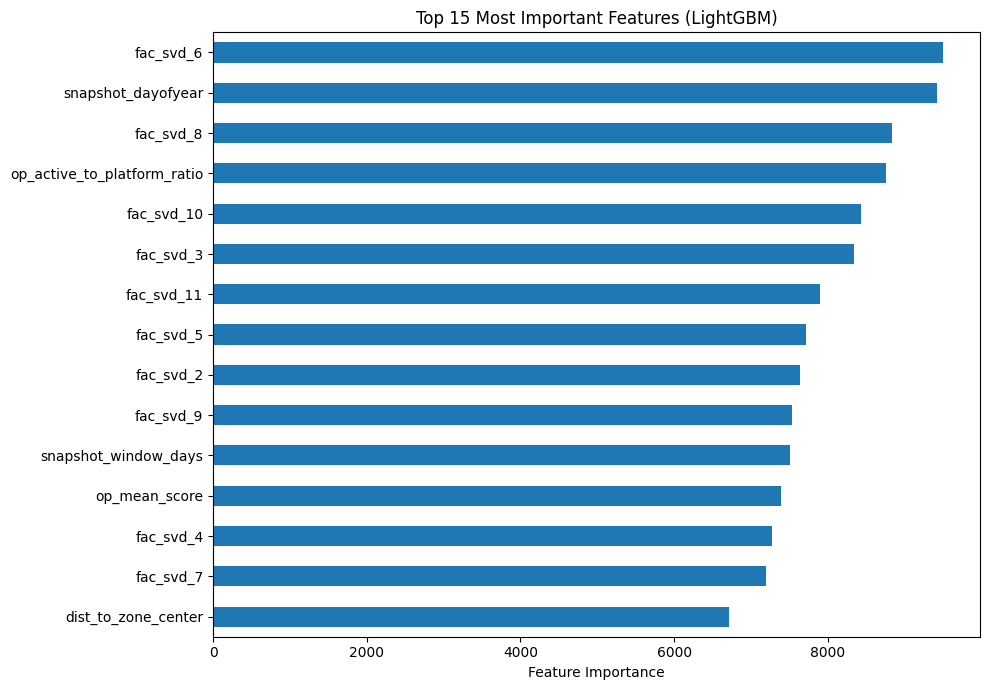

In [84]:
fitted_lgbm = fold_ensemble.named_estimators_['lgbm']

feature_importance = pd.Series(
    fitted_lgbm.feature_importances_,
    index=feature_names
).sort_values().tail(15)

plt.figure(figsize=(10, 7))

feature_importance.plot(
    kind='barh',
    title='Top 15 Most Important Features (LightGBM)'
)

plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

In [85]:
final_test_preds = np.argmax(
    test_preds * best_w,
    axis=1
) + 1

submission = pd.DataFrame({
    'ID': test_df['space_id'],
    'price_tier': final_test_preds
})

submission.to_csv('submission.csv', index=False)